In [ ]:
dataset = {
    "CreditScore": [720, 650, 580, 800, 710],
    "Income": [50000, 40000, 100000, 90000, 60000],
    "EmploymentHistory": ["5 years", "2 years", "1 year", "10 years", "7 years"],
    "ApprovalStatus": ["Approved", "Pending", "Rejected", "Approved", "Approved"]
}

import pandas as pd
data = pd.DataFrame(dataset)
data

,CreditScore,Income,EmploymentHistory,ApprovalStatus
0,720,50000,5 years,Approved
1,650,40000,2 years,Pending
2,580,30000,1 year,Rejected
3,800,90000,10 years,Approved
4,710,60000,7 years,Approved


In [2]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
data['EmploymentHistory_Encoded'] = le.fit_transform(data['EmploymentHistory'])
data

,CreditScore,Income,EmploymentHistory,ApprovalStatus,EmploymentHistory_Encoded
0,720,50000,5 years,Approved,3
1,650,40000,2 years,Pending,2
2,580,30000,1 year,Rejected,0
3,800,90000,10 years,Approved,1
4,710,60000,7 years,Approved,4


In [3]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(sparse_output=False)
encoded = encoder.fit_transform(data[['ApprovalStatus']])
encoded_data = pd.DataFrame(encoded,columns=encoder.get_feature_names_out(['ApprovalStatus']))
final_data = pd.concat([data, encoded_data],axis=1)
final_data

,CreditScore,Income,EmploymentHistory,ApprovalStatus,EmploymentHistory_Encoded,ApprovalStatus_Approved,ApprovalStatus_Pending,ApprovalStatus_Rejected
0,720,50000,5 years,Approved,3,1.0,0.0,0.0
1,650,40000,2 years,Pending,2,0.0,1.0,0.0
2,580,30000,1 year,Rejected,0,0.0,0.0,1.0
3,800,90000,10 years,Approved,1,1.0,0.0,0.0
4,710,60000,7 years,Approved,4,1.0,0.0,0.0


In [5]:
x = data[['EmploymentHistory_Encoded']]
y = data['Income']

In [6]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
model.fit(x,y)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [10]:
print(y)

0    50000
1    40000
2    30000
3    90000
4    60000
Name: Income, dtype: int64


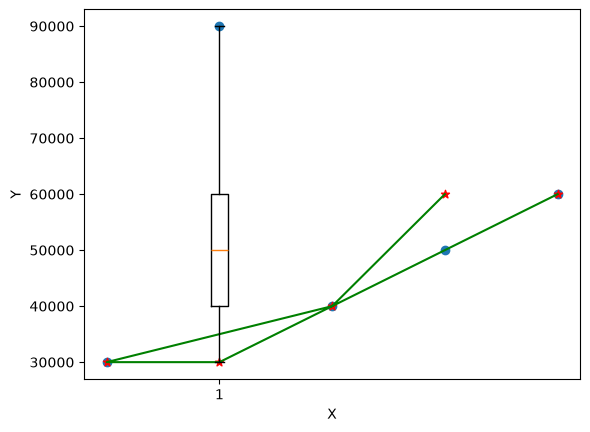

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(x,y)
plt.scatter(x,model.predict(x),color='red',marker='*',label='Predicted points')
plt.plot(x,model.predict(x),color='green',label='Regression line')
plt.boxplot(y)
plt.xlabel("X")
plt.ylabel("Y")
plt.show()